# Cyclus example notebook

This notebook is designed to walk the user through the various capabilities of the Cyclus/Watts interface.
It uses the OT-1 scenario from the SA&I campaign, which deploys various LWRs from 1960 to 2100.
The module reads the .sqlite output and functions allow extracting relevant data.

In [68]:
%load_ext autoreload
%autoreload 2

# Watts modules
from watts.plugin_cyclus import ResultsCyclus
from watts.parameters import Parameters
from watts.results import ExecInfo

# Other modules
import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1) Inputs

In [69]:
# Output file from Cyclus simulation
cyclus_output_path = './nuc46_nz50_ot1.sqlite'

In [70]:
# Enrichment-dependent inputs
natu_assay = 0.00711
tails_assay = 0.0025

In [71]:
# Parameters for the rest of the analysis
min_year = 2020 # Only analyze years >= min_year

## 2) Cyclus Watts object

In [72]:
# Create ResultsCyclus object
inputs = []
outputs = [cyclus_output_path]

result = ResultsCyclus(Parameters(), ExecInfo(1, 'cyclus', 'name', 1),
                    inputs, outputs)
# The main Cyclus-related object is a "CyclusOutput" object, located in result.obj
cyclus = result.obj


## 3) Get overall information

In [73]:
# Time-related parameters
print(f'Years in simulation: {cyclus.years}')
print(f'Duration (months): {cyclus.duration} -> {cyclus.duration/12} years')
print(f'Initial year/month: {cyclus.init_year}/{cyclus.init_month}')

Years in simulation: [1960.         1960.08333333 1960.16666667 ... 2100.75       2100.83333333
 2100.91666667]
Duration (months): 1692 -> 141.0 years
Initial year/month: 1960/1


In [74]:
# Agents
print(f'Number of agents: {len(cyclus.agent_dict)}')
print(f"Example agents:")
for i in range(5):
    print(f'\t{list(cyclus.agent_dict.keys())[i]}: {list(cyclus.agent_dict.values())[i]}')
print('\t...')

Number of agents: 454
Example agents:
	239: nat_u_source
	240: enrichment
	241: smr_enrichment
	242: ap1000_enrichment
	243: natrium_enr
	...


In [75]:
# Reactors
print('Number of reactor prototypes:', len(cyclus.reactors))
print(f"Example reactors: {cyclus.reactors[:5]} ...")

Number of reactor prototypes: 97
Example reactors: ['ANO-1' 'ANO-2' 'AP1000' 'BEAVER VALLEY-1' 'BEAVER VALLEY-2'] ...


In [76]:
# Nuclides
print(f"Number of nuclides: {len(cyclus.nucids)}")
print(f"Example nuclides: {cyclus.nucids[:5]} ...")

Number of nuclides: 1165
Example nuclides: [10010000 10020000 10030000 20030000 20040000] ...


## 4) Processing data

In [77]:
# Store years as integers (not months)
cyclus_years = np.array(list(sorted(set(cyclus.years.astype(int)))))

# For the rest of the analysis, we will only consider years >= min_year
years_idx = np.where(cyclus_years >= min_year)[0]
years = cyclus_years[years_idx]
print(f'Analyzing years: {years}')

Analyzing years: [2020 2021 2022 2023 2024 2025 2026 2027 2028 2029 2030 2031 2032 2033
 2034 2035 2036 2037 2038 2039 2040 2041 2042 2043 2044 2045 2046 2047
 2048 2049 2050 2051 2052 2053 2054 2055 2056 2057 2058 2059 2060 2061
 2062 2063 2064 2065 2066 2067 2068 2069 2070 2071 2072 2073 2074 2075
 2076 2077 2078 2079 2080 2081 2082 2083 2084 2085 2086 2087 2088 2089
 2090 2091 2092 2093 2094 2095 2096 2097 2098 2099 2100]


Reactors in that simulation are:
1) AP-1000: designated as the prototype 'AP1000'. In addition, VOGTLE-3 and VOGTLE-4 are also AP-1000 reactors
2) "Legacy" reactors, which are all the other reactors

In [78]:
AP1000_prototypes = ['AP1000', 'VOGTLE-3', 'VOGTLE-4']
# Get all the other reactor prototypes into a list "legacy_prototypes"
legacy_prototypes = [reactor for reactor in cyclus.reactors if reactor not in AP1000_prototypes]

# Check that AP-1000 reactors are indeed in the simulation, and raise an error if not
for prototype in AP1000_prototypes:
    if prototype not in cyclus.reactors:
        raise ValueError(f'Error: {prototype} not found in the reactor prototypes!')

print(f'AP-1000 reactor prototypes ({len(AP1000_prototypes)}): {AP1000_prototypes}')
print(f'Legacy reactor prototypes ({len(legacy_prototypes)}): {legacy_prototypes}')

# Construct a dictionary that maps each reactor prototype to its group
reactor_groups = {'AP-1000': AP1000_prototypes, 'Legacy': legacy_prototypes}

AP-1000 reactor prototypes (3): ['AP1000', 'VOGTLE-3', 'VOGTLE-4']
Legacy reactor prototypes (94): ['ANO-1', 'ANO-2', 'BEAVER VALLEY-1', 'BEAVER VALLEY-2', 'BRAIDWOOD-1', 'BRAIDWOOD-2', 'BROWNS FERRY-1', 'BROWNS FERRY-2', 'BROWNS FERRY-3', 'BRUNSWICK-1', 'BRUNSWICK-2', 'BYRON-1', 'BYRON-2', 'CALLAWAY-1', 'CALVERT CLIFFS-1', 'CALVERT CLIFFS-2', 'CATAWBA-1', 'CATAWBA-2', 'CLINTON-1', 'COLUMBIA', 'COMANCHE PEAK-1', 'COMANCHE PEAK-2', 'COOK-1', 'COOK-2', 'COOPER', 'DAVIS BESSE-1', 'DIABLO CANYON-1', 'DIABLO CANYON-2', 'DRESDEN-2', 'DRESDEN-3', 'FARLEY-1', 'FARLEY-2', 'FERMI-2', 'FITZPATRICK', 'GINNA', 'GRAND GULF-1', 'HARRIS-1', 'HATCH-1', 'HATCH-2', 'HOPE CREEK-1', 'INDIAN POINT-3', 'LASALLE-1', 'LASALLE-2', 'LIMERICK-1', 'LIMERICK-2', 'MCGUIRE-1', 'MCGUIRE-2', 'MILLSTONE-2', 'MILLSTONE-3', 'MONTICELLO', 'NINE MILE POINT-1', 'NINE MILE POINT-2', 'NORTH ANNA-1', 'NORTH ANNA-2', 'OCONEE-1', 'OCONEE-2', 'OCONEE-3', 'PALISADES', 'PALO VERDE-1', 'PALO VERDE-2', 'PALO VERDE-3', 'PEACH BOTTOM-2'

## 5) Low-level data extraction

The plugin allows for extracting any sql field from the cyclus sqlite output. Here is an example:

In [79]:
# Cyclus cursor (low-level access to the sqlite database)
cyclus.cur

In [80]:
# Extract distinct commodities from the transactions table
result_query = cyclus.sql_query('SELECT distinct(commodity) FROM transactions')
result_query

In [81]:
# Each row in the result is a dictionary
keys = [x.keys() for x in result_query]
keys

[['Commodity'],
 ['Commodity'],
 ['Commodity'],
 ['Commodity'],
 ['Commodity'],
 ['Commodity']]

In [82]:
# Extract the commodities as a list of strings
commodities = [x['commodity'] for x in result_query]
commodities

['natl_u', 'uox', 'tailings', 'uox_waste', 'ap1000_uox', 'uox_waste_ap1000']

## 6) Analysis

Functions operate roughly the same way:
- prototypes: one prototype name (string), a list of prototype names (list of strings), or all reactors (None, by default)
- return_sum: whether to return the sum over all prototypes (True) or a dictionary with each prototype (False)
Specific function requirements are described below when used.

### 6.1) Deployed capacity

In [83]:
# Power capacity deployment
cyclus.get_deployment_dict(yearly=False, return_sum=False) # If yearly=True, returns yearly capacity deployment (average over the year), otherwise monthly

{'ANO-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'ANO-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'AP1000': array([  0.  ,   0.  ,   0.  , ..., 390.95, 390.95, 390.95]),
 'BEAVER VALLEY-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'BEAVER VALLEY-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'BRAIDWOOD-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'BRAIDWOOD-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'BROWNS FERRY-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'BROWNS FERRY-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'BROWNS FERRY-3': array([0., 0., 0., ..., 0., 0., 0.]),
 'BRUNSWICK-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'BRUNSWICK-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'BYRON-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'BYRON-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'CALLAWAY-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'CALVERT CLIFFS-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'CALVERT CLIFFS-2': array([0., 0., 0., ..., 0., 0., 0.]),
 'CATAWBA-1': array([0., 0., 0., ..., 0., 0., 0.]),
 'CAT

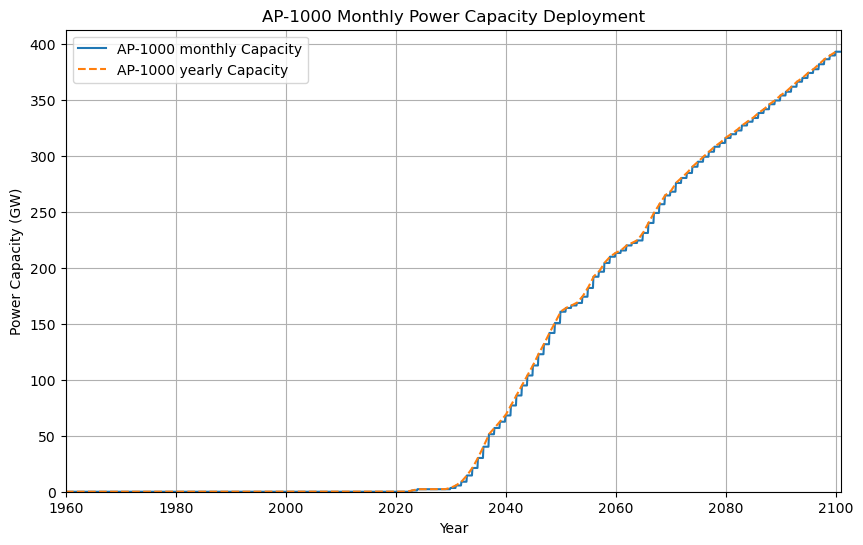

In [84]:
# Just for AP-1000 reactors, plot the monthly/yearly capacity deployment
ap1000_monthly_capacity = cyclus.get_deployment_dict(prototypes=AP1000_prototypes, yearly=False, return_sum=True)
ap1000_yearly_capacity = cyclus.get_deployment_dict(prototypes=AP1000_prototypes, yearly=True, return_sum=True)

plt.figure(figsize=(10, 6))
plt.plot(cyclus.years, ap1000_monthly_capacity, label='AP-1000 monthly Capacity')
plt.plot(cyclus_years, ap1000_yearly_capacity, label='AP-1000 yearly Capacity', linestyle='--')
plt.xlabel('Year')
plt.ylabel('Power Capacity (GW)')
plt.title('AP-1000 Monthly Power Capacity Deployment')
plt.grid()
plt.xlim(cyclus.years[0], cyclus.years[-1])
plt.ylim(0)
plt.legend()

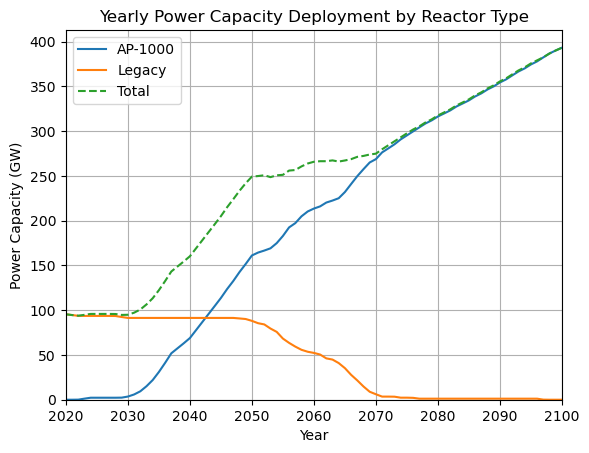

In [85]:
# We can also easily aggregate the yearly capacities by reactor types and plot them (and add the total capacity evolution)
# Focus on years >= min_year

# Reactor groups yearly capacity
for group_name, prototypes in reactor_groups.items():
    group_yearly_capacity = cyclus.get_deployment_dict(prototypes=prototypes, yearly=True, return_sum=True)[years_idx]
    plt.plot(years, group_yearly_capacity, label=f'{group_name}')

# Total yearly capacity
total_yearly_capacity = cyclus.get_deployment_dict(prototypes=None, yearly=True, return_sum=True)[years_idx]
plt.plot(years, total_yearly_capacity, label='Total', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Power Capacity (GW)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('Yearly Power Capacity Deployment by Reactor Type')
plt.grid()
plt.legend()

### 6.2) Fuel demand and discharge

In [86]:
# Reactors demand
cyclus.stock_fuel_demand(return_sum=False)

{'ANO-1': array([    0.   ,     0.   ,     0.   ,     0.   ,     0.   ,     0.   ,
            0.   ,     0.   ,     0.   ,     0.   ,     0.   ,     0.   ,
            0.   ,     0.   ,     0.   ,     0.   , 62714.538, 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846,     0.   , 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846,     0.   ,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
            0.   , 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
        20904.846,     0.   , 20904.846, 20904.846, 20904.846, 20904.846,
        20904.846, 20904.846,     0.   , 20904.846, 20904.846, 20904.846,
        20904.846, 20904.846, 20904.846,     0.   , 20904.846, 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846,     0.   , 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846,     0.   ,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
            0.   , 20904.846,

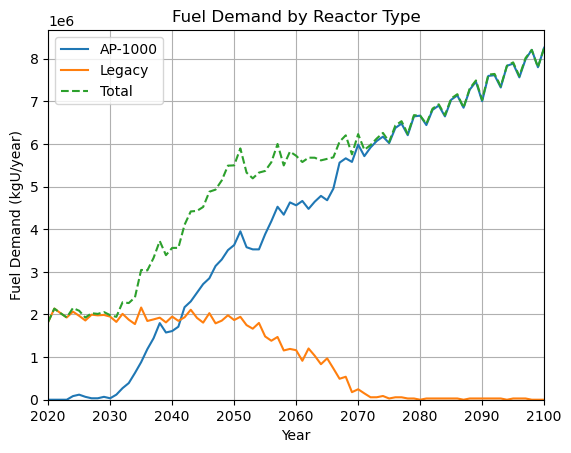

In [87]:
# Aggregate demand by reactor groups and plot them (and add the total demand evolution)

# Reactor groups demand
for group_name, prototypes in reactor_groups.items():
    group_demand = cyclus.stock_fuel_demand(prototypes=prototypes, return_sum=True)[years_idx]
    plt.plot(years, group_demand, label=f'{group_name}')

# Total demand
total_demand = cyclus.stock_fuel_demand(prototypes=None, return_sum=True)[years_idx]
plt.plot(years, total_demand, label='Total', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Fuel Demand (kgU/year)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('Fuel Demand by Reactor Type')
plt.legend()
plt.grid()

In [88]:
# Discharged fuel
cyclus.stock_fuel_discharged(return_sum=False)

{'ANO-1': array([    0.   ,     0.   ,     0.   ,     0.   ,     0.   ,     0.   ,
            0.   ,     0.   ,     0.   ,     0.   ,     0.   ,     0.   ,
            0.   ,     0.   ,     0.   ,     0.   ,     0.   , 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846,     0.   , 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846,     0.   ,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
            0.   , 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
        20904.846,     0.   , 20904.846, 20904.846, 20904.846, 20904.846,
        20904.846, 20904.846,     0.   , 20904.846, 20904.846, 20904.846,
        20904.846, 20904.846, 20904.846,     0.   , 20904.846, 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846,     0.   , 20904.846,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846,     0.   ,
        20904.846, 20904.846, 20904.846, 20904.846, 20904.846, 20904.846,
            0.   , 20904.846,

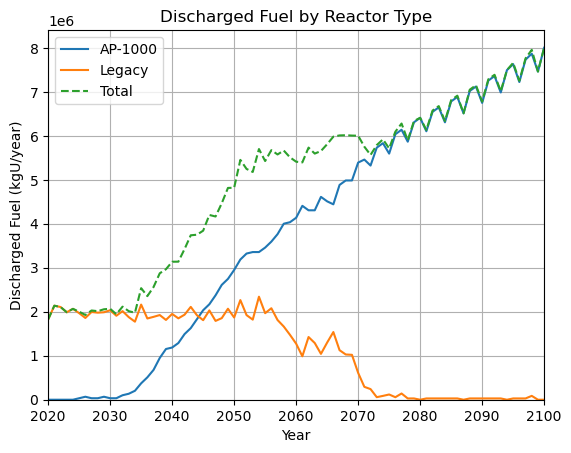

In [89]:
# Aggregate discharged fuel by reactor groups and plot them (and add the total discharged fuel evolution)

# Reactor groups discharged fuel
for group_name, prototypes in reactor_groups.items():
    group_discharged = cyclus.stock_fuel_discharged(prototypes=prototypes, return_sum=True)[years_idx]
    plt.plot(years, group_discharged, label=f'{group_name}')

# Total discharged fuel
total_discharged = cyclus.stock_fuel_discharged(prototypes=None, return_sum=True)[years_idx]
plt.plot(years, total_discharged, label='Total', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Discharged Fuel (kgU/year)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('Discharged Fuel by Reactor Type')
plt.legend()
plt.grid()

### 6.3) Enrichment-related quantities

In [90]:
# Reactors enrichments
cyclus.get_enrichments() # there is no return_sum option here since enrichments are per reactor

{'ANO-1': array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.045, 0.045,
        0.045, 0.045, 0.045, 0.045, 0.   , 0.045, 0.045, 0.045, 0.045,
        0.045, 0.045, 0.   , 0.045, 0.045, 0.045, 0.045, 0.045, 0.045,
        0.   , 0.045, 0.045, 0.045, 0.045, 0.045, 0.045, 0.   , 0.045,
        0.045, 0.045, 0.045, 0.045, 0.045, 0.   , 0.045, 0.045, 0.045,
        0.045, 0.045, 0.045, 0.   , 0.045, 0.045, 0.045, 0.045, 0.045,
        0.045, 0.   , 0.045, 0.045, 0.045, 0.045, 0.045, 0.045, 0.   ,
        0.045, 0.045, 0.045, 0.045, 0.045, 0.045, 0.   , 0.045, 0.045,
        0.045, 0.045, 0.045, 0.045, 0.   , 0.045, 0.045, 0.045, 0.045,
        0.045, 0.045, 0.   , 0.045, 0.045, 0.045, 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.  

In [91]:
# Enrichments are yearly, so we can take the unique non-zero enrichments and print them

# Get enrichments for all reactors
enrichments = cyclus.get_enrichments(prototypes=None)

# Get unique non-zero enrichments 
unique_enrichments = {reactor: np.unique(np.round(enrichments[reactor][enrichments[reactor] > 0], 8)) for reactor in enrichments}

# Check that all reactors have exactly one unique enrichment, otherwise raise an error
for reactor in unique_enrichments:
    if len(unique_enrichments[reactor]) != 1:
        raise ValueError(f'Error: Reactor {reactor} has {len(unique_enrichments[reactor])} unique non-zero enrichments: {unique_enrichments[reactor]}! Expected exactly one unique enrichment per reactor.')
unique_enrichments = {reactor: unique_enrichments[reactor][0] for reactor in unique_enrichments}

# Print the unique non-zero enrichments
for reactor, enrichment in unique_enrichments.items():
    print(f'Reactor {reactor}: Enrichment = {enrichment:.4%}')

Reactor ANO-1: Enrichment = 4.5000%
Reactor ANO-2: Enrichment = 4.5000%
Reactor AP1000: Enrichment = 4.8000%
Reactor BEAVER VALLEY-1: Enrichment = 4.5000%
Reactor BEAVER VALLEY-2: Enrichment = 4.5000%
Reactor BRAIDWOOD-1: Enrichment = 4.5000%
Reactor BRAIDWOOD-2: Enrichment = 4.5000%
Reactor BROWNS FERRY-1: Enrichment = 4.5000%
Reactor BROWNS FERRY-2: Enrichment = 4.5000%
Reactor BROWNS FERRY-3: Enrichment = 4.5000%
Reactor BRUNSWICK-1: Enrichment = 4.5000%
Reactor BRUNSWICK-2: Enrichment = 4.5000%
Reactor BYRON-1: Enrichment = 4.5000%
Reactor BYRON-2: Enrichment = 4.5000%
Reactor CALLAWAY-1: Enrichment = 4.5000%
Reactor CALVERT CLIFFS-1: Enrichment = 4.5000%
Reactor CALVERT CLIFFS-2: Enrichment = 4.5000%
Reactor CATAWBA-1: Enrichment = 4.5000%
Reactor CATAWBA-2: Enrichment = 4.5000%
Reactor CLINTON-1: Enrichment = 4.5000%
Reactor COLUMBIA: Enrichment = 4.5000%
Reactor COMANCHE PEAK-1: Enrichment = 4.5000%
Reactor COMANCHE PEAK-2: Enrichment = 4.5000%
Reactor COOK-1: Enrichment = 4.500

All further enrichment-related quantities require the natu_assay and tails_assay inputs
A cascade_splits argument is available to control if tails of a lower category are used as feed for a higher category
In addition, a split_cat boolean argument is added to decide whether to split the output quantities into categories 
based on the cascade_splits argument or to return the total of all categories
The enrichments are automatically obtained in the background

In [92]:
# SWU
# Cat-III: 0%<=enr<10%, Cat-II: 10%<=enr<20%, Cat-I: 20%<=enr<=100%
cyclus.stock_fuel_swu(natu_assay=natu_assay, tails_assay=tails_assay, return_sum=False, cascade_splits=[0.1, 0.2], split_cat=True)

{'ANO-1': array([[     0.        ,      0.        ,      0.        ,
              0.        ,      0.        ,      0.        ,
              0.        ,      0.        ,      0.        ,
              0.        ,      0.        ,      0.        ,
              0.        ,      0.        ,      0.        ,
              0.        , 430918.67667102, 143639.55889034,
         143639.55889034, 143639.55889034, 143639.55889034,
         143639.55889034,      0.        , 143639.55889034,
         143639.55889034, 143639.55889034, 143639.55889034,
         143639.55889034, 143639.55889034,      0.        ,
         143639.55889034, 143639.55889034, 143639.55889034,
         143639.55889034, 143639.55889034, 143639.55889034,
              0.        , 143639.55889034, 143639.55889034,
         143639.55889034, 143639.55889034, 143639.55889034,
         143639.55889034,      0.        , 143639.55889034,
         143639.55889034, 143639.55889034, 143639.55889034,
         143639.55889034, 14363

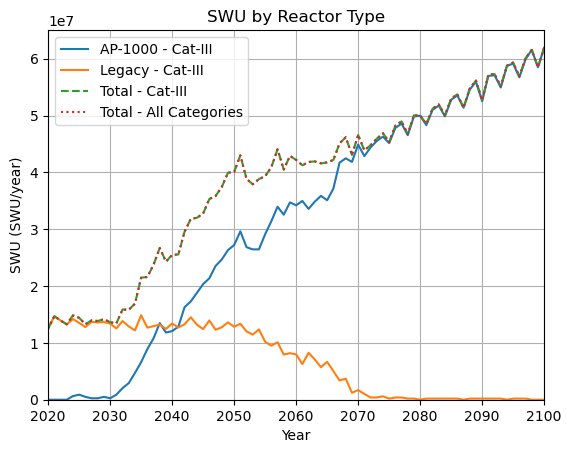

In [93]:
# Aggregate SWU by reactor groups and plot them (and add the total SWU evolution)
# Here, there should be only cat-III enrichment (all LEU reactors)

# Reactor groups SWU
for group_name, prototypes in reactor_groups.items():
    group_swu_per_cat = cyclus.stock_fuel_swu(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True, split_cat=True)[:,years_idx]
    for i in range(len(group_swu_per_cat)):
        # Pass if 0: no need to plot zero SWU
        if np.all(group_swu_per_cat[i] == 0):
            continue
        group_swu = group_swu_per_cat[i]
        plt.plot(years, group_swu, label=f'{group_name} - Cat-{["III", "II", "I"][i]}')
    
# Total SWU per category
total_swu_per_cat = cyclus.stock_fuel_swu(prototypes=None, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True, split_cat=True)[:, years_idx]
for i in range(len(total_swu_per_cat)):
    # Pass if 0: no need to plot zero SWU
    if np.all(total_swu_per_cat[i] == 0):
        continue
    total_swu = total_swu_per_cat[i]
    plt.plot(years, total_swu, label=f'Total - Cat-{["III", "II", "I"][i]}', linestyle='--')

# Total SWU (all categories)
total_swu = cyclus.stock_fuel_swu(prototypes=None, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True, split_cat=False)[years_idx]
plt.plot(years, total_swu, label='Total - All Categories', linestyle=':')

plt.xlabel('Year')
plt.ylabel('SWU (SWU/year)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('SWU by Reactor Type')
plt.legend()
plt.grid()


In [94]:
# Tails
cyclus.stock_fuel_tails(natu_assay=natu_assay, tails_assay=tails_assay, return_sum=False, cascade_splits=[0.1, 0.2])

{'ANO-1': array([     0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
        515456.36547072, 171818.78849024, 171818.78849024, 171818.78849024,
        171818.78849024, 171818.78849024,      0.        , 171818.78849024,
        171818.78849024, 171818.78849024, 171818.78849024, 171818.78849024,
        171818.78849024,      0.        , 171818.78849024, 171818.78849024,
        171818.78849024, 171818.78849024, 171818.78849024, 171818.78849024,
             0.        , 171818.78849024, 171818.78849024, 171818.78849024,
        171818.78849024, 171818.78849024, 171818.78849024,      0.        ,
        171818.78849024, 171818.78849024, 171818.78849024, 171818.78849024,
        171818.78849024, 171818.78849024,      0.        , 171818.78849024,
   

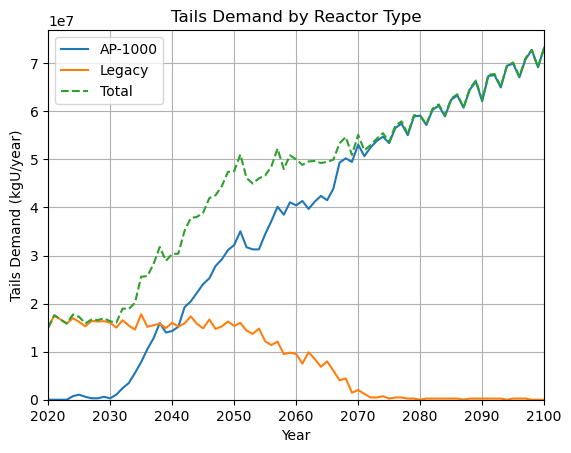

In [95]:
# Aggregate tails by reactor groups and plot them (and add the total tails evolution)

# Reactor groups tails
for group_name, prototypes in reactor_groups.items():
    group_swu = cyclus.stock_fuel_tails(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx]
    plt.plot(years, group_swu, label=f'{group_name}')
    
# Total tails
total_swu = cyclus.stock_fuel_tails(prototypes=None, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx]
plt.plot(years, total_swu, label='Total', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Tails Demand (kgU/year)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('Tails Demand by Reactor Type')
plt.legend()
plt.grid()

In [96]:
# Natural uranium demand
cyclus.stock_fuel_natu(natu_assay=natu_assay, tails_assay=tails_assay, return_sum=False, cascade_splits=[0.1, 0.2])

{'ANO-1': array([     0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
             0.        ,      0.        ,      0.        ,      0.        ,
        578170.90347072, 192723.63449024, 192723.63449024, 192723.63449024,
        192723.63449024, 192723.63449024,      0.        , 192723.63449024,
        192723.63449024, 192723.63449024, 192723.63449024, 192723.63449024,
        192723.63449024,      0.        , 192723.63449024, 192723.63449024,
        192723.63449024, 192723.63449024, 192723.63449024, 192723.63449024,
             0.        , 192723.63449024, 192723.63449024, 192723.63449024,
        192723.63449024, 192723.63449024, 192723.63449024,      0.        ,
        192723.63449024, 192723.63449024, 192723.63449024, 192723.63449024,
        192723.63449024, 192723.63449024,      0.        , 192723.63449024,
   

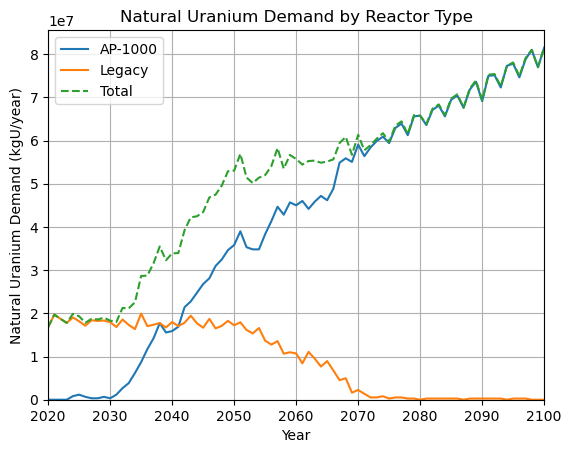

In [97]:
# Aggregate natural uranium demand by reactor groups and plot them (and add the total natural uranium demand evolution)

# Reactor groups natural uranium demand
for group_name, prototypes in reactor_groups.items():
    group_natu = cyclus.stock_fuel_natu(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx]
    plt.plot(years, group_natu, label=f'{group_name}')
    
# Total natural uranium demand
total_natu = cyclus.stock_fuel_natu(prototypes=None, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx]
plt.plot(years, total_natu, label='Total', linestyle='--')

plt.xlabel('Year')
plt.ylabel('Natural Uranium Demand (kgU/year)')
plt.xlim(min_year, years[-1])
plt.ylim(0)
plt.title('Natural Uranium Demand by Reactor Type')
plt.legend()
plt.grid()

## 7) Going further

This section is to go further in plotting the data.

In [98]:
fields_function_mapping = {
    'Power Capacity (GW)': lambda prototypes: cyclus.get_deployment_dict(prototypes=prototypes, yearly=True, return_sum=True)[years_idx],
    'Fuel Demand (kgU/year)': lambda prototypes: cyclus.stock_fuel_demand(prototypes=prototypes, return_sum=True)[years_idx],
    'Discharged Fuel (kgU/year)': lambda prototypes: cyclus.stock_fuel_discharged(prototypes=prototypes, return_sum=True)[years_idx],
    'SWU (SWU/year)': lambda prototypes: cyclus.stock_fuel_swu(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True, split_cat=False)[years_idx],
    'Tails Demand (kgU/year)': lambda prototypes: cyclus.stock_fuel_tails(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx],
    'Natural Uranium Demand (kgU/year)': lambda prototypes: cyclus.stock_fuel_natu(prototypes=prototypes, natu_assay=natu_assay, tails_assay=tails_assay, return_sum=True)[years_idx]
}

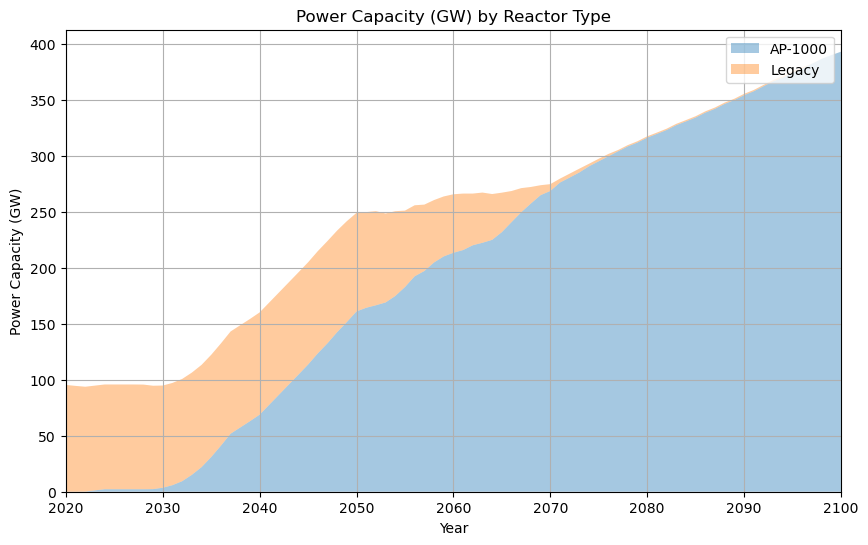

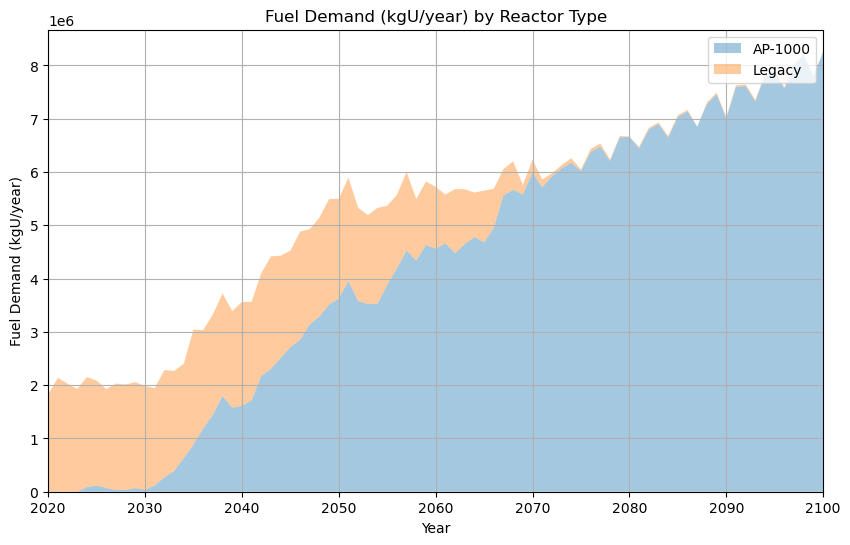

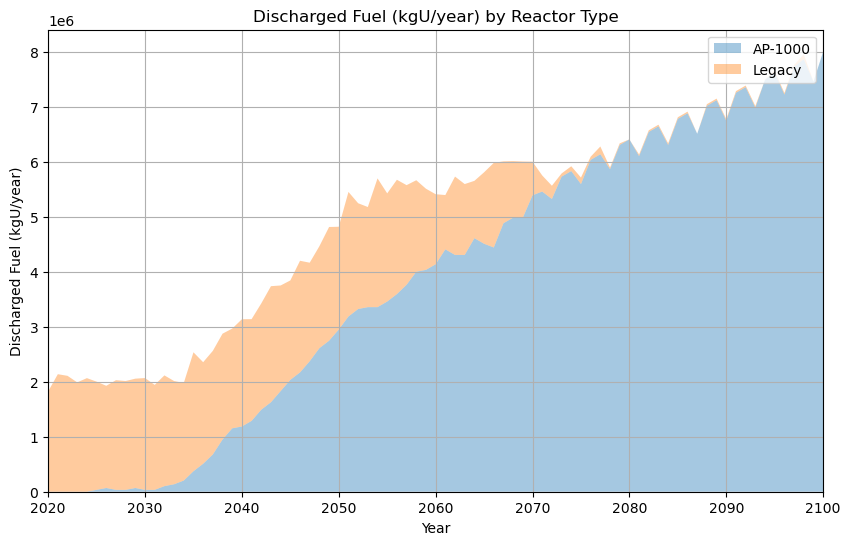

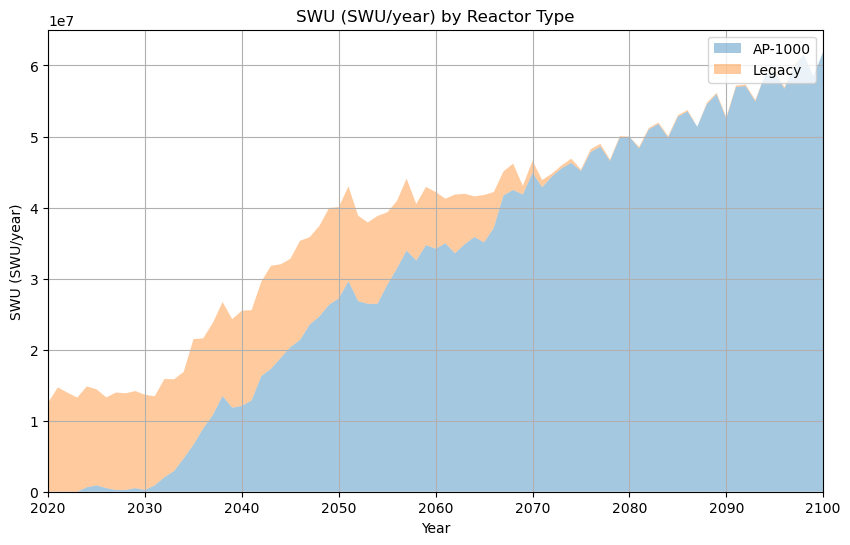

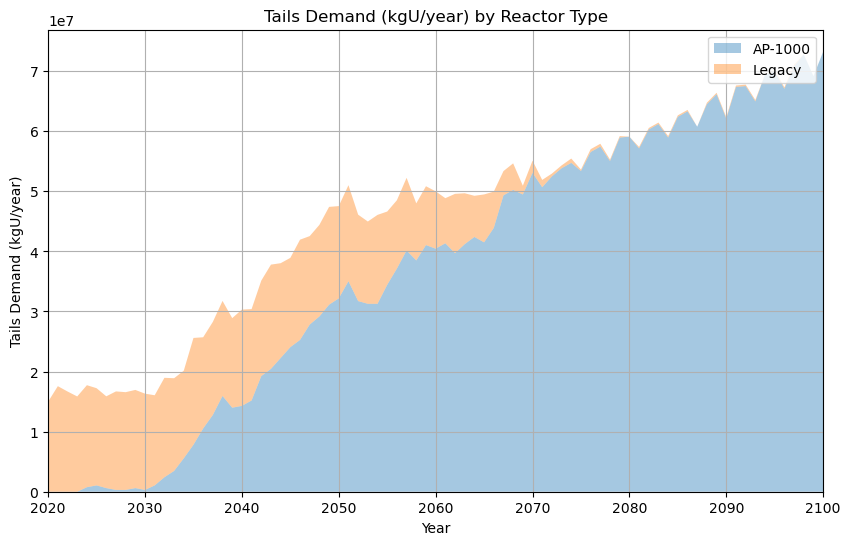

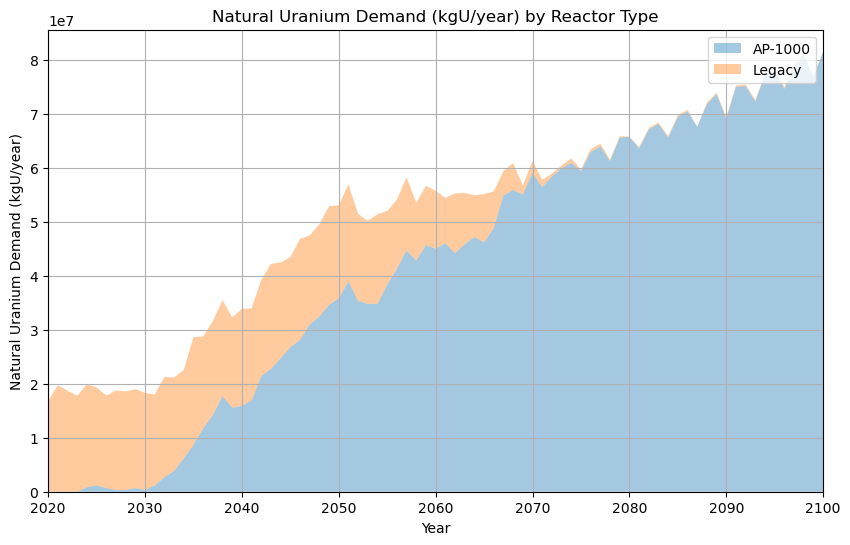

In [99]:
# Stacked area plot of each field of interest (e.g., power capacity, fuel demand, discharged fuel, SWU, tails, natural uranium demand) by reactor groups
for field, func in fields_function_mapping.items():
    plt.figure(figsize=(10, 6))
    group_values = []
    group_labels = []
    for group_name, prototypes in reactor_groups.items():
        group_value = func(prototypes)
        group_values.append(group_value)
        group_labels.append(group_name)
    
    # Stacked area plot
    plt.stackplot(years, group_values, labels=group_labels, alpha=0.4)    
    plt.xlabel('Year')
    plt.ylabel(field)
    plt.xlim(min_year, years[-1])
    plt.ylim(0)
    plt.title(f'{field} by Reactor Type')
    plt.legend()
    plt.grid()
    plt.show()

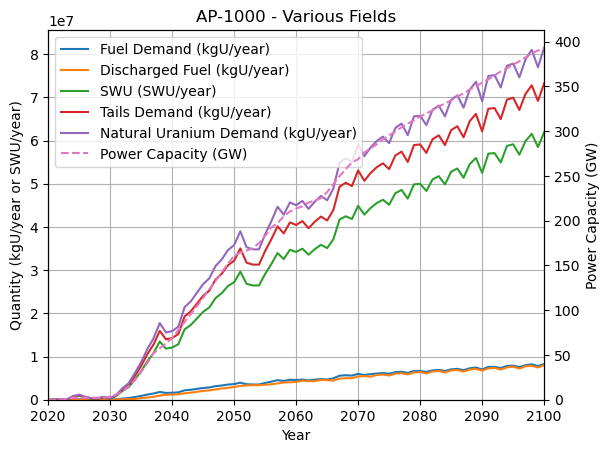

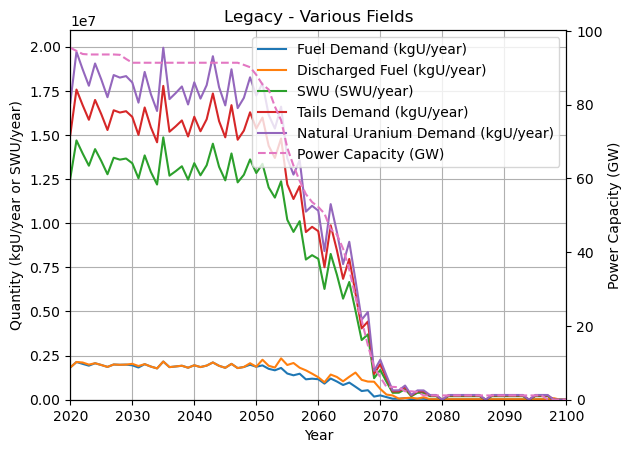

In [100]:
# Line plot of each reactor type for all fields of interest (e.g., power capacity, fuel demand, discharged fuel, SWU, tails, natural uranium demand)
for reactor_group in reactor_groups:
    fig, ax = plt.subplots()
    ax2 = ax.twinx() # For power capacity
    prototypes = reactor_groups[reactor_group]
    for field, func in fields_function_mapping.items():
        values = func(prototypes)
        if field == 'Power Capacity (GW)':
            ax2.plot(years, values, label=field, color=f'C{len(fields_function_mapping)}', linestyle='--')
        else:
            ax.plot(years, values, label=field)

    ax2.set_ylabel('Power Capacity (GW)')
    ax2.set_ylim(0)
    ax.set_ylim(0)
    ax.set_xlabel('Year')
    ax.set_ylabel('Quantity (kgU/year or SWU/year)')
    ax.set_xlim(min_year, years[-1])
    ax.set_title(f'{reactor_group} - Various Fields')
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, loc='best')
    ax.grid()
    plt.show()